# 신항 1~7부두 연도별 물동량과 하역능력 비교

이 분석은 `port_all.csv`의 연도별 부두별 물동량을 집계하고, 첨부된 신항 컨테이너부두 현황 자료의 하역능력과 비교하는 것을 목적으로 한다.

## 분석 기준

- 분석 대상은 신항1부두부터 신항7부두까지이다.
- 가로축은 연도, 세로축은 물동량과 하역능력의 단위인 천 TEU이다.
- 같은 연도와 부두에 여러 행이 있을 수 있으므로 `물동량_천TEU`를 연도·부두별로 합산해 연간 총 물동량을 계산한다.
- 사진에 제시된 하역능력은 신항1 2,090천 TEU, 신항2 3,790천 TEU, 신항3 2,310천 TEU, 신항4 1,930천 TEU, 신항5 2,440천 TEU, 신항6 1,950천 TEU, 신항7 1,950천 TEU이다.
- 각 부두별 패널에서 실선은 연도별 총 물동량, 점선은 해당 부두의 하역능력 기준선이다. 실선이 점선보다 높으면 해당 연도의 물동량이 연간 하역능력을 초과한 것으로 해석한다.
- 데이터에 아직 운영되지 않은 부두의 연도가 없으면 임의로 0으로 채우지 않고 결측으로 둔다.


In [2]:
from pathlib import Path
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

# 노트북 실행 위치가 C:/final 또는 C:/final/EDA인 경우 모두 대응
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "fragment.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from fragment import load_dataset

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


## 데이터 불러오기

`fragment.py`에 정의된 `load_dataset()` 함수를 사용해 `data/port_all.csv`를 불러온다. 함수 내부에서 기본 인코딩으로 읽지 못하는 경우 `euc-kr` 인코딩으로 다시 읽도록 되어 있다.


In [3]:
df = load_dataset("port_all")
if df is None:
    raise FileNotFoundError("data/port_all.csv 파일을 찾을 수 없습니다.")

df.head()


,연도,부두,물동량_천TEU,하역능력_천TEU,가동률_pct,안벽길이_m,접안선석수,CC수,운영개시연도,운영연수,자동화수준_현재_초안,자동화수준_설명,신항여부,완전자동화여부
0,2017,신항2부두,4531,3790,119.6,2000,6,22,2006,11,1,부분 자동화(분석용 초안),1,0
1,2017,신항1부두,2689,2090,128.7,1200,3,12,2010,7,1,부분 자동화(분석용 초안),1,0
2,2017,신선대부두,2261,2236,101.1,1500,5,15,1991,26,0,유인 중심(분석용 초안),0,0
3,2017,신항3부두,2219,2310,96.1,1100,4,12,2009,8,2,야드 자동화(분석용 초안),1,0
4,2017,신항4부두,2069,1930,107.2,1150,4,12,2010,7,2,야드 자동화(분석용 초안),1,0


In [4]:
# 사진에 제시된 신항 1~7부두의 하역능력(천 TEU)
handling_capacity = {
    "신항1부두": 2090,
    "신항2부두": 3790,
    "신항3부두": 2310,
    "신항4부두": 1930,
    "신항5부두": 2440,
    "신항6부두": 1950,
    "신항7부두": 1950,
}
target_piers = list(handling_capacity)

# 자료형을 정리하고 분석 대상 부두만 선택
df["연도"] = pd.to_numeric(df["연도"], errors="coerce").astype("Int64")
df["물동량_천TEU"] = pd.to_numeric(df["물동량_천TEU"], errors="coerce")
df = df[df["부두"].isin(target_piers)].copy()

annual_volume = (
    df.dropna(subset=["연도", "물동량_천TEU"])
      .groupby(["연도", "부두"], as_index=False)["물동량_천TEU"]
      .sum()
      .sort_values(["부두", "연도"])
)

capacity_df = pd.DataFrame({
    "부두": target_piers,
    "하역능력_천TEU": [handling_capacity[pier] for pier in target_piers],
})

annual_volume.head()


,연도,부두,물동량_천TEU
0,2017,신항1부두,2689
5,2018,신항1부두,2478
10,2019,신항1부두,2404
15,2020,신항1부두,2744
20,2021,신항1부두,2737


## 그래프 작성 기준

부두별 연간 총 물동량을 실선으로 그리고, 사진에서 확인한 하역능력을 같은 단위의 수평 점선으로 표시한다. 부두마다 하역능력 규모가 다르므로 한 그래프에 7개 부두를 겹쳐 그리지 않고 7개 패널로 나누어 추이를 비교한다. 이렇게 하면 연도별 물동량 변화와 각 부두의 하역능력 초과 여부를 동시에 확인할 수 있다.


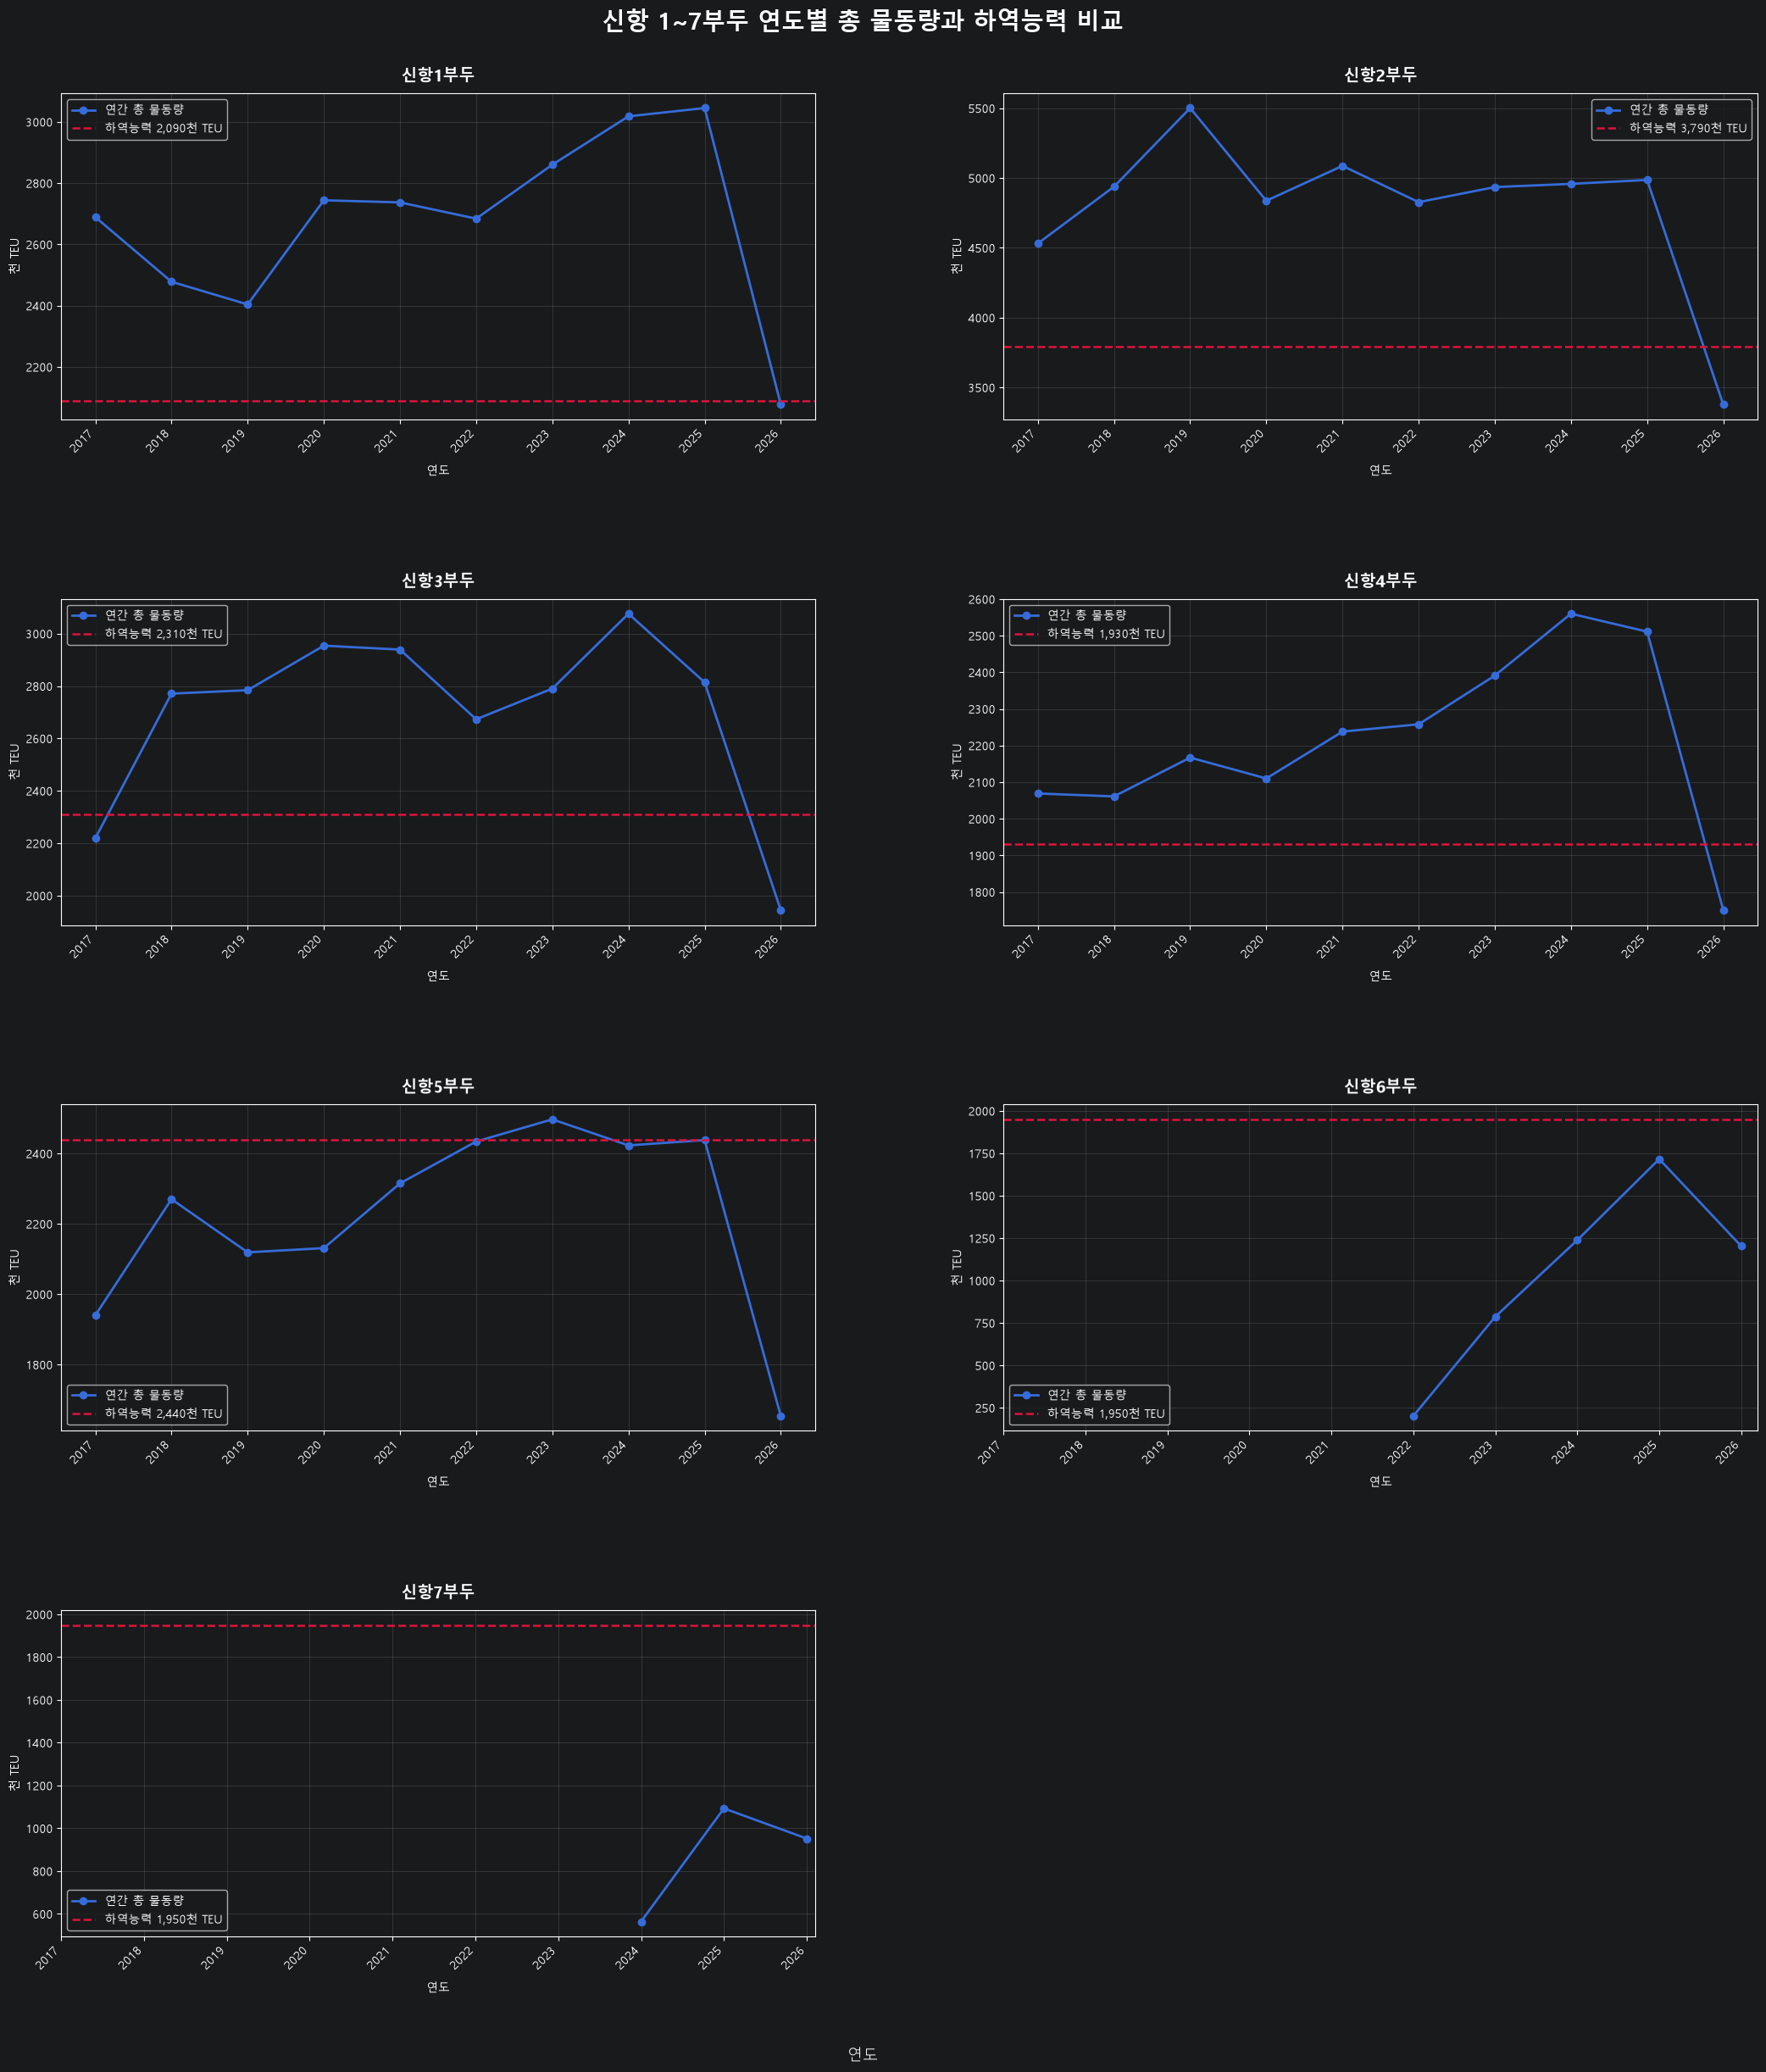

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(22, 25), sharex=False)
axes = axes.flatten()
all_years = sorted(annual_volume["연도"].dropna().unique())

for ax, pier in zip(axes, target_piers):
    pier_data = annual_volume[annual_volume["부두"] == pier]
    capacity = handling_capacity[pier]

    ax.plot(
        pier_data["연도"],
        pier_data["물동량_천TEU"],
        marker="o",
        linewidth=2,
        label="연간 총 물동량",
    )
    ax.axhline(
        capacity,
        color="crimson",
        linestyle="--",
        linewidth=1.8,
        label=f"하역능력 {capacity:,}천 TEU",
    )

    # 모든 패널에 연도 눈금과 x축 이름을 표시
    ax.set_xticks(all_years)
    ax.set_xticklabels([str(year) for year in all_years], rotation=45, ha="right")
    ax.set_xlabel("연도", labelpad=8)
    ax.set_title(pier, fontsize=14, fontweight="bold", pad=10)
    ax.set_ylabel("천 TEU")
    ax.grid(alpha=0.25)
    ax.legend(loc="best", fontsize=10)

# 마지막 빈 패널 제거
fig.delaxes(axes[-1])
fig.suptitle("신항 1~7부두 연도별 총 물동량과 하역능력 비교", fontsize=20, fontweight="bold")
fig.supxlabel("연도", fontsize=13)
fig.subplots_adjust(left=0.07, right=0.98, bottom=0.07, top=0.94, hspace=0.55, wspace=0.25)
plt.show()


## 하역능력 대비 물동량 확인

아래 표는 그래프 해석을 보조하기 위해 연도별 물동량을 하역능력으로 나눈 비율을 계산한다. 100%를 초과하면 해당 연도의 물동량이 기준 하역능력보다 큰 경우이다.


In [6]:
utilization = annual_volume.copy()
utilization["하역능력_천TEU"] = utilization["부두"].map(handling_capacity)
utilization["하역능력 대비 물동량(%)"] = (
    utilization["물동량_천TEU"] / utilization["하역능력_천TEU"] * 100
).round(1)

utilization.sort_values(["연도", "부두"]).head(14)
utilization


,연도,부두,물동량_천TEU,하역능력_천TEU,하역능력 대비 물동량(%)
0,2017,신항1부두,2689,2090,128.7
5,2018,신항1부두,2478,2090,118.6
10,2019,신항1부두,2404,2090,115.0
15,2020,신항1부두,2744,2090,131.3
20,2021,신항1부두,2737,2090,131.0
25,2022,신항1부두,2684,2090,128.4
31,2023,신항1부두,2860,2090,136.8
37,2024,신항1부두,3018,2090,144.4
44,2025,신항1부두,3045,2090,145.7
51,2026,신항1부두,2077,2090,99.4
